> **Record only — do not rerun.** This is the continued-pretraining run on the first 11-document corpus (2026-11-09), kept for the decision log. Held-out perplexity 19.84 → 18.97 (epoch 2 of 3; early stop). The current pipeline is `CV_Assistant_Phase2.ipynb` at the repository root, which runs `train_cpt.py`, `train_sft.py` and `score.py` on the 20-document corpus.

# CV Assistant — Phase 2, Step 1: Continued pretraining

This notebook continues training **GPT-2 small (124M)** on our 11 CV-guide documents so it picks up CV vocabulary.

**What it does, in order**
1. **Setup**: get the project, install libraries, choose settings
2. **Data**: count tokens, hold out one whole document for testing
3. **Before training**: measure the base model (perplexity + 5 sample completions)
4. **Training**: up to 3 passes over the data, stop early if the held-out loss gets worse
5. **After training**: measure the best checkpoint the same way, compare before/after
6. **Save**: everything goes to Google Drive; a results ZIP is downloaded for GitHub

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**. It takes a few minutes.

Each *Run all* creates a new, time-stamped run folder in Google Drive, so earlier runs are never overwritten.

*Next steps (not in this notebook): supervised fine-tuning (SFT) and scoring the three models on the 30 test questions.*

## 1. Setup

In [1]:
# Get the project files from GitHub (skipped if they are already here).
import os
if not os.path.exists("/content/CV_Assistant"):
    !git clone https://github.com/rahafabumwise/CV_Assistant.git /content/CV_Assistant
%cd /content/CV_Assistant

Cloning into '/content/CV_Assistant'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (133/133), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 133 (delta 46), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (133/133), 187.93 KiB | 1.42 MiB/s, done.
Resolving deltas: 100% (46/46), done.
/content/CV_Assistant


In [2]:
# Install the library versions that worked for our first run.
# The uninstall line removes Colab packages that conflict with these versions (we don't use them).
%pip install -q "transformers==4.57.1" "accelerate==1.11.0"
%pip uninstall -q -y gradio gradio-client diffusers hf-gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import json
import math
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import transformers
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

# ---------------- ALL SETTINGS ARE HERE ----------------
SETTINGS = {
    "model_name": "openai-community/gpt2",
    "seed": 42,
    # whole document kept aside to measure perplexity (never trained on)
    "heldout_document": "oregon_cv_preparation.txt",
    # training
    "block_size": 512,
    "max_epochs": 3,
    "batch_size": 2,
    "learning_rate": 5e-5,
    "weight_decay": 0.01,
    "max_grad_norm": 1.0,
    # perplexity measurement (sliding window)
    "eval_context": 512,
    "eval_stride": 256,
    # the same 5 prompts are completed before and after training
    "completion_prompts": [
        "When writing your first CV,",
        "An effective education section",
        "To describe your work experience,",
        "When including volunteer experience on a CV,",
        "A clearly formatted CV",
    ],
    "completion_max_new_tokens": 80,
}

PROJECT = Path("/content/CV_Assistant")
DOCUMENTS = PROJECT / "data/cpt/documents"
DRIVE_EXPERIMENTS = Path("/content/drive/MyDrive/CV_Assistant/experiments")
# --------------------------------------------------------

set_seed(SETTINGS["seed"])
assert torch.cuda.is_available(), "No GPU: Runtime → Change runtime type → T4 GPU, then run again."
DEVICE = "cuda"

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130 | Transformers: 4.57.1


In [4]:
# Connect Google Drive and create a new folder for this run.
# Checkpoints are large, so they are saved here and NOT in GitHub.
from google.colab import drive
drive.mount("/content/drive")

RUN_NAME = datetime.now(timezone.utc).strftime("cpt_%Y%m%d_%H%M%S")
RUN_FOLDER = DRIVE_EXPERIMENTS / RUN_NAME
RESULTS = RUN_FOLDER / "results"
RESULTS.mkdir(parents=True, exist_ok=False)

(RUN_FOLDER / "settings.json").write_text(json.dumps(SETTINGS, indent=2))
(RUN_FOLDER / "environment.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True))

print("This run is saved in:", RUN_FOLDER)

Mounted at /content/drive
This run is saved in: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_121543


## 2. Data: token counts and the held-out split

We split by **whole document** (not by sentence), so no text from the held-out document leaks into training.
10 documents are used for training and 1 is held out (about 11% of the tokens).

In [5]:
tokenizer = AutoTokenizer.from_pretrained(SETTINGS["model_name"])
tokenizer.pad_token = tokenizer.eos_token   # GPT-2 has no padding token; reuse end-of-text

def count_tokens(text):
    return len(tokenizer.encode(text, add_special_tokens=False))

documents = sorted(DOCUMENTS.glob("*.txt"))
assert len(documents) == 11, f"Expected 11 documents in {DOCUMENTS}, found {len(documents)}"

train_files = [p for p in documents if p.name != SETTINGS["heldout_document"]]
heldout_files = [p for p in documents if p.name == SETTINGS["heldout_document"]]
assert len(heldout_files) == 1, "Held-out document not found. Check SETTINGS['heldout_document']."

for p in documents:
    role = "HELD OUT" if p in heldout_files else "train"
    print(f"{role:9} {p.name:45} {count_tokens(p.read_text(encoding='utf-8')):>6,} tokens")

train_tokens = sum(count_tokens(p.read_text(encoding="utf-8")) for p in train_files)
heldout_tokens = sum(count_tokens(p.read_text(encoding="utf-8")) for p in heldout_files)
total = train_tokens + heldout_tokens
print(f"\nTotal {total:,} tokens | train {train_tokens:,} ({train_tokens/total:.0%}) | held out {heldout_tokens:,} ({heldout_tokens/total:.0%})")

split = {
    "method": "whole-document split",
    "train": [p.relative_to(PROJECT).as_posix() for p in train_files],
    "heldout": [p.relative_to(PROJECT).as_posix() for p in heldout_files],
    "train_tokens": train_tokens,
    "heldout_tokens": heldout_tokens,
}
(RESULTS / "cpt_split.json").write_text(json.dumps(split, indent=2))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (2381 > 1024). Running this sequence through the model will result in indexing errors


HELD OUT  oregon_cv_preparation.txt                        890 tokens
train     oregon_resume_formats.txt                        661 tokens
train     oregon_resume_sections_and_guidelines.txt      2,381 tokens
train     tru_action_verbs.txt                             339 tokens
train     tru_education_training_and_certificates.txt      445 tokens
train     tru_employment_or_work_experience.txt            420 tokens
train     tru_hobbies_interest.txt                         145 tokens
train     tru_modern_resume_formatting.txt               1,362 tokens
train     tru_overall_format.txt                           554 tokens
train     tru_transferable_skills.txt                      497 tokens
train     tru_volunteering_community_involvement.txt       233 tokens

Total 7,927 tokens | train 7,037 (89%) | held out 890 (11%)


758

In [6]:
# Leakage check: is any 15-word sequence shared between training and held-out text?
# (This only finds exact copies, not paraphrases.)
import re

def word_sequences(path, length=15):
    words = re.findall(r"\b\w+\b", path.read_text(encoding="utf-8").lower())
    return {tuple(words[i:i + length]) for i in range(len(words) - length + 1)}

heldout_seq = set().union(*(word_sequences(p) for p in heldout_files))
shared = {p.name: len(word_sequences(p) & heldout_seq) for p in train_files}
shared = {name: n for name, n in shared.items() if n}
print("Shared 15-word sequences:", shared if shared else "none")

Shared 15-word sequences: none


## 3. Before training: measure the base model

**Held-out perplexity** = how surprised the model is by the held-out document (lower is better).
The document is longer than one 512-token window, so a window slides forward 256 tokens at a time;
tokens already scored are masked with `-100`, so each token is counted exactly once.

In [7]:
model = AutoModelForCausalLM.from_pretrained(SETTINGS["model_name"], use_safetensors=True).to(DEVICE)
model.config.pad_token_id = tokenizer.pad_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id
print(f"{SETTINGS['model_name']}: {sum(p.numel() for p in model.parameters()):,} parameters")

heldout_text = "\n\n".join(p.read_text(encoding="utf-8") for p in heldout_files)

@torch.no_grad()
def heldout_perplexity(model):
    model.eval()
    ids = tokenizer.encode(heldout_text, add_special_tokens=False)
    context, stride = SETTINGS["eval_context"], SETTINGS["eval_stride"]
    total_loss, total_scored, previous_end = 0.0, 0, 0
    for start in range(0, len(ids), stride):
        end = min(start + context, len(ids))
        new_tokens = end - previous_end
        inputs = torch.tensor([ids[start:end]], device=DEVICE)
        labels = inputs.clone()
        labels[:, :-new_tokens] = -100              # don't score tokens already scored
        scored = (labels[:, 1:] != -100).sum().item()
        if scored:
            loss = model(input_ids=inputs, labels=labels, use_cache=False).loss
            total_loss += loss.item() * scored
            total_scored += scored
        previous_end = end
        if end == len(ids):
            break
    mean_loss = total_loss / total_scored
    return {"loss": mean_loss, "perplexity": math.exp(mean_loss), "scored_tokens": total_scored}

@torch.no_grad()
def complete_prompts(model):
    model.eval()
    outputs = []
    for prompt in SETTINGS["completion_prompts"]:
        inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
        generated = model.generate(
            **inputs, do_sample=False, num_beams=1,           # greedy = same output every time
            max_new_tokens=SETTINGS["completion_max_new_tokens"],
            pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
        new_tokens = generated[0, inputs["input_ids"].shape[1]:]
        outputs.append(tokenizer.decode(new_tokens, skip_special_tokens=True))
    return outputs

before = heldout_perplexity(model)
before_completions = complete_prompts(model)

print(f"Base model: held-out loss {before['loss']:.4f}, perplexity {before['perplexity']:.2f} "
      f"({before['scored_tokens']} tokens)")
for prompt, text in zip(SETTINGS["completion_prompts"], before_completions):
    print(f"\n▶ {prompt}{text[:300]}")

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

openai-community/gpt2: 124,439,808 parameters


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Base model: held-out loss 2.9879, perplexity 19.84 (889 tokens)

▶ When writing your first CV, you should always be aware of the following:

What you are writing is not your own.

You are not writing for yourself.

You are not writing for your company.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.

You are not writing for yourself.



▶ An effective education section of the bill would require that the state provide a minimum of $1,000 per student for each student enrolled in a public school.

The bill would also require that the state provide a minimum of $1,000 per student for each student enrolled in a private school.

The bill would also require that the sta

▶ To describe your work experience, please see the following:

How do I get started?

You can start by downloading the latest version of the app from the App Store.

How do I get started with the app?

You can start by downloading the latest version of the app from the 

## 4. Continued pretraining

The training documents are joined (with an end-of-text token between them) and cut into 512-token blocks.
The last block is padded; padding is masked with `-100` so it does not count in the loss.

After each pass (epoch) we measure held-out loss and save a checkpoint.
**Early stopping:** if held-out loss gets worse than the previous epoch, we stop — the model has started to memorise the training text (overfitting).
The epoch with the lowest held-out loss is selected.

In [8]:
class TrainingBlocks(Dataset):
    def __init__(self, files, block_size):
        ids = []
        for p in files:
            ids += tokenizer.encode(p.read_text(encoding="utf-8"), add_special_tokens=False)
            ids.append(tokenizer.eos_token_id)          # separator between documents
        self.blocks = []
        for start in range(0, len(ids), block_size):
            chunk = ids[start:start + block_size]
            pad = block_size - len(chunk)
            self.blocks.append({
                "input_ids": torch.tensor(chunk + [tokenizer.pad_token_id] * pad),
                "attention_mask": torch.tensor([1] * len(chunk) + [0] * pad),
                "labels": torch.tensor(chunk + [-100] * pad),
            })
        self.n_tokens = len(ids)
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, i):
        return self.blocks[i]

train_data = TrainingBlocks(train_files, SETTINGS["block_size"])
train_loader = DataLoader(train_data, batch_size=SETTINGS["batch_size"], shuffle=True,
                          generator=torch.Generator().manual_seed(SETTINGS["seed"]))
print(f"{train_data.n_tokens:,} training tokens → {len(train_data)} blocks → {len(train_loader)} steps per epoch")

7,047 training tokens → 14 blocks → 7 steps per epoch


In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=SETTINGS["learning_rate"],
                              weight_decay=SETTINGS["weight_decay"])

history = []          # one row per epoch
step_losses = []      # training loss at every step (for the curve)
best = {"epoch": None, "loss": float("inf"), "checkpoint": None}
previous_val = before["loss"]

for epoch in range(1, SETTINGS["max_epochs"] + 1):
    model.train()
    epoch_loss, epoch_tokens = 0.0, 0
    for batch in train_loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        loss = model(**batch, use_cache=False).loss
        if not torch.isfinite(loss):
            raise RuntimeError("Loss became NaN/inf — stop and inspect.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), SETTINGS["max_grad_norm"])
        optimizer.step()

        scored = (batch["labels"][:, 1:] != -100).sum().item()
        epoch_loss += loss.item() * scored
        epoch_tokens += scored
        step_losses.append(loss.item())

    val = heldout_perplexity(model)
    checkpoint = RUN_FOLDER / "checkpoints" / f"epoch_{epoch}"
    model.save_pretrained(checkpoint, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint)

    history.append({"epoch": epoch, "train_loss": epoch_loss / epoch_tokens,
                    "val_loss": val["loss"], "val_perplexity": val["perplexity"],
                    "checkpoint": str(checkpoint)})
    print(f"Epoch {epoch}: train loss {history[-1]['train_loss']:.4f} | "
          f"held-out loss {val['loss']:.4f} | perplexity {val['perplexity']:.2f}")

    if val["loss"] < best["loss"]:
        best = {"epoch": epoch, "loss": val["loss"], "checkpoint": str(checkpoint)}
    if val["loss"] > previous_val:
        print("Held-out loss went up → stopping early (overfitting).")
        break
    previous_val = val["loss"]

print(f"\nSelected: epoch {best['epoch']} → {best['checkpoint']}")
(RESULTS / "cpt_history.json").write_text(json.dumps(history, indent=2))
(RESULTS / "cpt_step_losses.json").write_text(json.dumps(step_losses))

Epoch 1: train loss 3.5657 | held-out loss 2.9618 | perplexity 19.33
Epoch 2: train loss 3.1976 | held-out loss 2.9429 | perplexity 18.97
Epoch 3: train loss 2.9361 | held-out loss 2.9573 | perplexity 19.25
Held-out loss went up → stopping early (overfitting).

Selected: epoch 2 → /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_121543/checkpoints/epoch_2


413

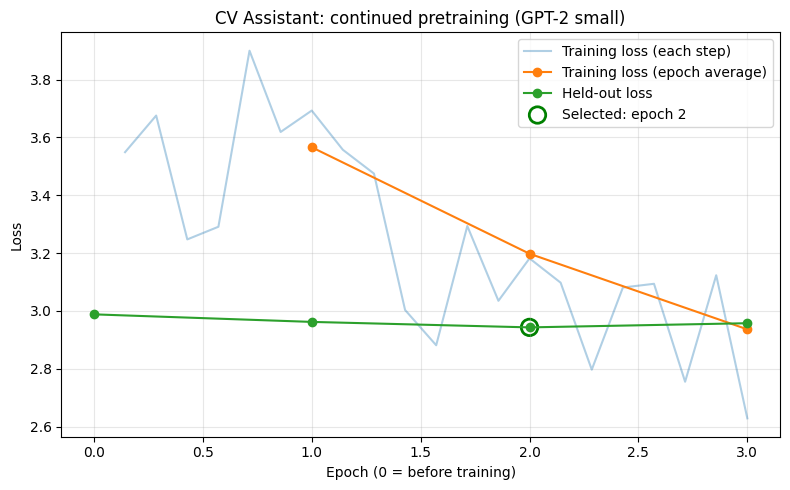

In [10]:
# Loss curves: training loss per step and per epoch, held-out loss per epoch (0 = before training).
steps_per_epoch = len(train_loader)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([(i + 1) / steps_per_epoch for i in range(len(step_losses))], step_losses,
        alpha=0.35, label="Training loss (each step)")
ax.plot([h["epoch"] for h in history], [h["train_loss"] for h in history],
        marker="o", label="Training loss (epoch average)")
ax.plot([0] + [h["epoch"] for h in history], [before["loss"]] + [h["val_loss"] for h in history],
        marker="o", label="Held-out loss")
ax.scatter([best["epoch"]], [best["loss"]], s=140, facecolors="none", edgecolors="green",
           linewidths=2, label=f"Selected: epoch {best['epoch']}")
ax.set(xlabel="Epoch (0 = before training)", ylabel="Loss",
       title="CV Assistant: continued pretraining (GPT-2 small)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "cpt_loss_curve.png", dpi=200)
plt.show()

## 5. After training: measure the selected checkpoint

We reload the **selected** epoch (not simply the last one) and measure it exactly as we measured the base model.

In [11]:
del model, optimizer
torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(best["checkpoint"], use_safetensors=True).to(DEVICE)
model.generation_config.pad_token_id = tokenizer.pad_token_id

after = heldout_perplexity(model)
after_completions = complete_prompts(model)

print(f"Held-out perplexity: {before['perplexity']:.2f} (base) → {after['perplexity']:.2f} (epoch {best['epoch']})")
for prompt, b, a in zip(SETTINGS["completion_prompts"], before_completions, after_completions):
    print(f"\n▶ {prompt}\n  BEFORE: {b[:250]!r}\n  AFTER : {a[:250]!r}")

Held-out perplexity: 19.84 (base) → 18.97 (epoch 2)

▶ When writing your first CV,
  BEFORE: ' you should always be aware of the following:\n\nWhat you are writing is not your own.\n\nYou are not writing for yourself.\n\nYou are not writing for your company.\n\nYou are not writing for yourself.\n\nYou are not writing for yourself.\n\nYou are not writing '
  AFTER : ' you should always include a brief description of your skills, interests, and accomplishments. This will help you build a strong foundation for your resume.\n\nFor example, if you have a resume that includes a section on your interests, you can include'

▶ An effective education section
  BEFORE: ' of the bill would require that the state provide a minimum of $1,000 per student for each student enrolled in a public school.\n\nThe bill would also require that the state provide a minimum of $1,000 per student for each student enrolled in a private'
  AFTER : ' is a section of the curriculum that is designed to help students u

## 6. Save the results

In [12]:
summary = {
    "run": RUN_NAME,
    "settings": SETTINGS,
    "split": split,
    "heldout_before": before,
    "heldout_after": after,
    "epochs": history,
    "selected_epoch": best["epoch"],
    "selected_checkpoint": best["checkpoint"],
}
(RESULTS / "cpt_summary.json").write_text(json.dumps(summary, indent=2))
(RESULTS / "cpt_completions.json").write_text(json.dumps(
    [{"prompt": p, "before": b, "after": a}
     for p, b, a in zip(SETTINGS["completion_prompts"], before_completions, after_completions)], indent=2))

# Download the small results (no checkpoints) so they can be uploaded to GitHub → results/
archive = shutil.make_archive(f"/content/{RUN_NAME}_results", "zip", RESULTS)
from google.colab import files
files.download(archive)

print("Results folder in Drive:", RESULTS)
print("Selected checkpoint (use this to start SFT):", best["checkpoint"])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Results folder in Drive: /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_121543/results
Selected checkpoint (use this to start SFT): /content/drive/MyDrive/CV_Assistant/experiments/cpt_20261109_121543/checkpoints/epoch_2
